# Dataset overview -- v1.0

Exploratory plots for `data/v1/pages.jsonl`: **6,201 pages x 18 labels**, 500 articles.

Run top to bottom (Kernel > Restart & Run All). Each figure is also saved to
`results/figures/` when `SAVE = True`.

In [1]:
import json
import sys
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "figure.figsize": (10, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
})

SAVE = True

## 0. Load

The repo root is found by walking up until `data/v1/pages.jsonl` appears, so the
notebook works from `notebooks/` or from the root.

In [2]:
ROOT = Path.cwd().resolve()
while not (ROOT / "data" / "v1" / "pages.jsonl").exists():
    if ROOT.parent == ROOT:
        raise SystemExit("Cannot find data/v1/pages.jsonl -- open this notebook inside the repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from dataset import CANONICAL_LABELS, FIELD_ORDER

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

rows = [json.loads(line) for line in (ROOT / "data/v1/pages.jsonl").open(encoding="utf-8")]
meta = [json.loads(line) for line in (ROOT / "data/v1/metadata.jsonl").open(encoding="utf-8")]

# drop the raw text: keeps the frame small and printable
df = pd.DataFrame([{k: v for k, v in r.items() if k != "text"} for r in rows])
df["field"] = pd.Categorical(df["field"], categories=list(FIELD_ORDER), ordered=True)

by_doc = defaultdict(list)
for r in rows:
    by_doc[r["manuscript_id"]].append(r)
for rs in by_doc.values():
    rs.sort(key=lambda r: r["page"])

print(f"pages     {len(df):,}")
print(f"articles  {len(meta):,}")
print(f"labels    {len(CANONICAL_LABELS)}")
print(f"manual    {(df.label_source == 'manual').sum():,}")
print(f"inherited {(df.label_source == 'inherited').sum():,}")
df.head(3)

pages     6,201
articles  500
labels    18
manual    2,215
inherited 3,986


,sample_id,manuscript_id,field,article_type,page,n_pages,rel_pos,n_chars,labels,labels_raw,labels_covered,section_id,label_source,is_section_start,n_labels_covered,y
0,2503.08689v1.pdf#p1,2503.08689v1.pdf,cs,preprint,1,12,0.0833,4131,"[title, abstract, introduction]","[{'label': 'title', 'raw': None}, {'label': 'a...","[title, abstract, introduction]",2503.08689v1.pdf-s01,manual,True,3,"[1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,2503.08689v1.pdf#p2,2503.08689v1.pdf,cs,preprint,2,12,0.1667,5347,[background],"[{'label': 'background', 'raw': 'related work'}]",[background],2503.08689v1.pdf-s02,manual,True,1,"[0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,2503.08689v1.pdf#p3,2503.08689v1.pdf,cs,preprint,3,12,0.2500,3929,[method],"[{'label': 'method', 'raw': None}]",[method],2503.08689v1.pdf-s03,manual,True,1,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, ..."


In [3]:
def savefig(name):
    if not SAVE:
        return
    plt.gcf().savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved", (FIG / f"{name}.png").relative_to(ROOT))

## 1. Corpus

- **Pages per article**: how uneven the corpus is. A handful of long papers carry many samples.
- **Characters per page**: extraction quality. A spike near 0 means scanned or image-only pages.
- **Labels per page**: 5,329 pages have one label, 872 have more (the multi-label annotation pages).
- **Articles and pages per field**: the six domains that the leave-one-field-out experiment will use.

saved results\figures\01_corpus.png


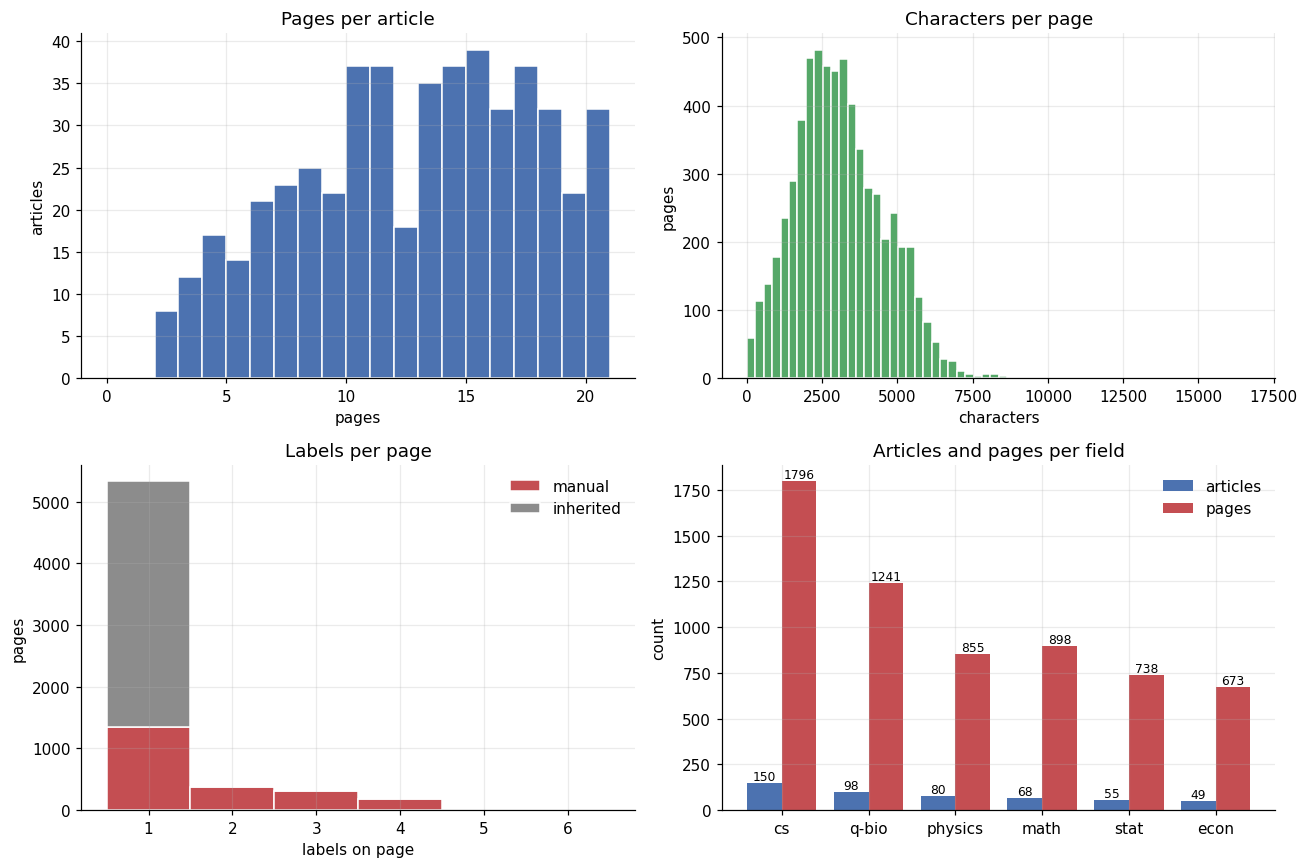

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

pages_per_doc = df.groupby("manuscript_id", observed=True).size()
axes[0, 0].hist(pages_per_doc, bins=range(0, pages_per_doc.max() + 2), color="#4c72b0", edgecolor="white")
axes[0, 0].set(title="Pages per article", xlabel="pages", ylabel="articles")

axes[0, 1].hist(df["n_chars"], bins=60, color="#55a868", edgecolor="white")
axes[0, 1].set(title="Characters per page", xlabel="characters", ylabel="pages")

bins = np.arange(0.5, df["n_labels_covered"].max() + 1.5, 1)
axes[1, 0].hist(
    [df.loc[df.label_source == "manual", "n_labels_covered"],
     df.loc[df.label_source == "inherited", "n_labels_covered"]],
    bins=bins, stacked=True, label=["manual", "inherited"],
    color=["#c44e52", "#8c8c8c"], edgecolor="white",
)
axes[1, 0].set(title="Labels per page", xlabel="labels on page", ylabel="pages")
axes[1, 0].legend(frameon=False)

field_articles = df.groupby("field", observed=True)["manuscript_id"].nunique().reindex(FIELD_ORDER)
field_pages = df["field"].value_counts().reindex(FIELD_ORDER)
x = np.arange(len(FIELD_ORDER))
w = 0.4
axes[1, 1].bar(x - w / 2, field_articles.values, w, label="articles", color="#4c72b0")
axes[1, 1].bar(x + w / 2, field_pages.values, w, label="pages", color="#c44e52")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(FIELD_ORDER)
axes[1, 1].set(title="Articles and pages per field", ylabel="count")
axes[1, 1].legend(frameon=False)
for i, (a, p) in enumerate(zip(field_articles.values, field_pages.values)):
    axes[1, 1].text(i - w / 2, a, str(a), ha="center", va="bottom", fontsize=8)
    axes[1, 1].text(i + w / 2, p, str(p), ha="center", va="bottom", fontsize=8)

fig.tight_layout()
savefig("01_corpus")
plt.show()

## 2. Label support

`manual` is what i annotated. `inherited` is pages that carried the last body
label forward. Front-matter labels (`title`, `abstract`, `keywords`) are
manual-only by construction, so their grey segment is zero.

The ranking is the class imbalance the models face: `introduction` is ~39% of
pages, `materials` ~1%.

saved results\figures\02_label_support.png


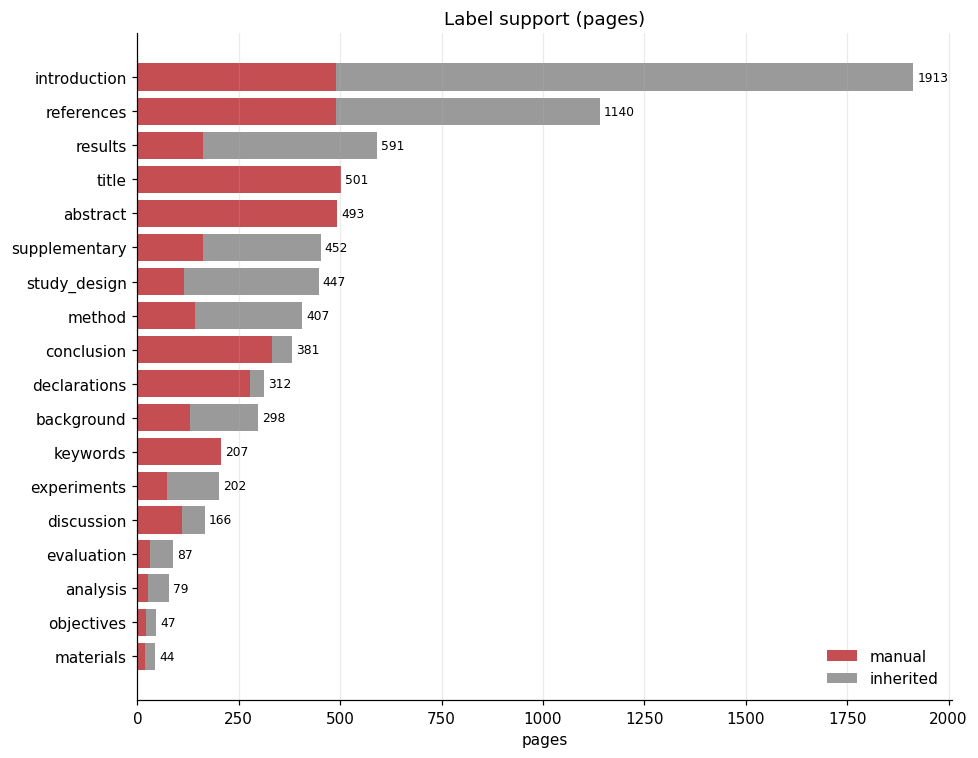

,manual,inherited,total
introduction,490,1423,1913
references,490,650,1140
results,163,428,591
title,501,0,501
abstract,493,0,493
supplementary,162,290,452
study_design,115,332,447
method,143,264,407
conclusion,331,50,381
declarations,279,33,312


In [5]:
man, cov = Counter(), Counter()
for r in rows:
    man.update(r["labels"])
    cov.update(r["labels_covered"])

support = pd.DataFrame({
    "manual": [man[l] for l in CANONICAL_LABELS],
    "inherited": [cov[l] - man[l] for l in CANONICAL_LABELS],
}, index=list(CANONICAL_LABELS))
support["total"] = support.sum(axis=1)
support = support.sort_values("total")

fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(support))
ax.barh(y, support["manual"], color="#c44e52", label="manual")
ax.barh(y, support["inherited"], left=support["manual"], color="#9a9a9a", label="inherited")
ax.set_yticks(y)
ax.set_yticklabels(support.index)
ax.set(title="Label support (pages)", xlabel="pages")
ax.legend(frameon=False, loc="lower right")
for i, total in enumerate(support["total"]):
    ax.text(total + 10, i, f"{total}", va="center", fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig("02_label_support")
plt.show()

support.sort_values("total", ascending=False)

### Label x field

Share of each field's pages carrying a label. Rows sum to more than 100% because
a page can carry several labels. This is where domain differences show up:
`materials` and `study_design` are concentrated in q-bio, `experiments` in cs.

saved results\figures\03_label_by_field.png


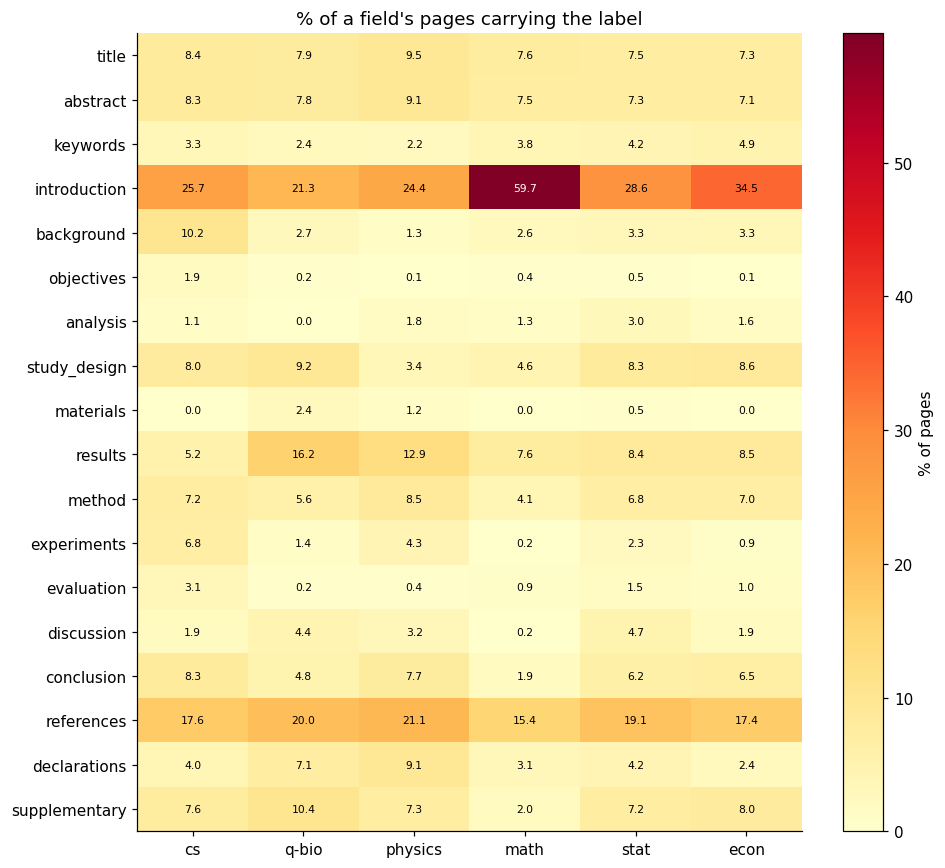

In [6]:
tab = pd.DataFrame(0, index=list(CANONICAL_LABELS), columns=list(FIELD_ORDER), dtype=int)
for r in rows:
    for l in r["labels_covered"]:
        tab.loc[l, r["field"]] += 1

field_page_counts = df["field"].value_counts().reindex(FIELD_ORDER)
share = tab.div(field_page_counts, axis=1) * 100

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(share.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(FIELD_ORDER)))
ax.set_xticklabels(FIELD_ORDER)
ax.set_yticks(range(len(CANONICAL_LABELS)))
ax.set_yticklabels(CANONICAL_LABELS)
ax.set_title("% of a field's pages carrying the label")
vmax = share.values.max()
for i in range(len(CANONICAL_LABELS)):
    for j in range(len(FIELD_ORDER)):
        v = share.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.6 * vmax else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of pages")
fig.tight_layout()
savefig("03_label_by_field")
plt.show()

## 3. Section structure

### Where each section first appears

Relative page position (0 = first page, 1 = last). This is the positional prior
that the rule-based features in the improved model will use: `title`/`abstract`
cluster at 0.08, `references` near the end. Boxes exclude outliers.

saved results\figures\04_first_occurrence.png


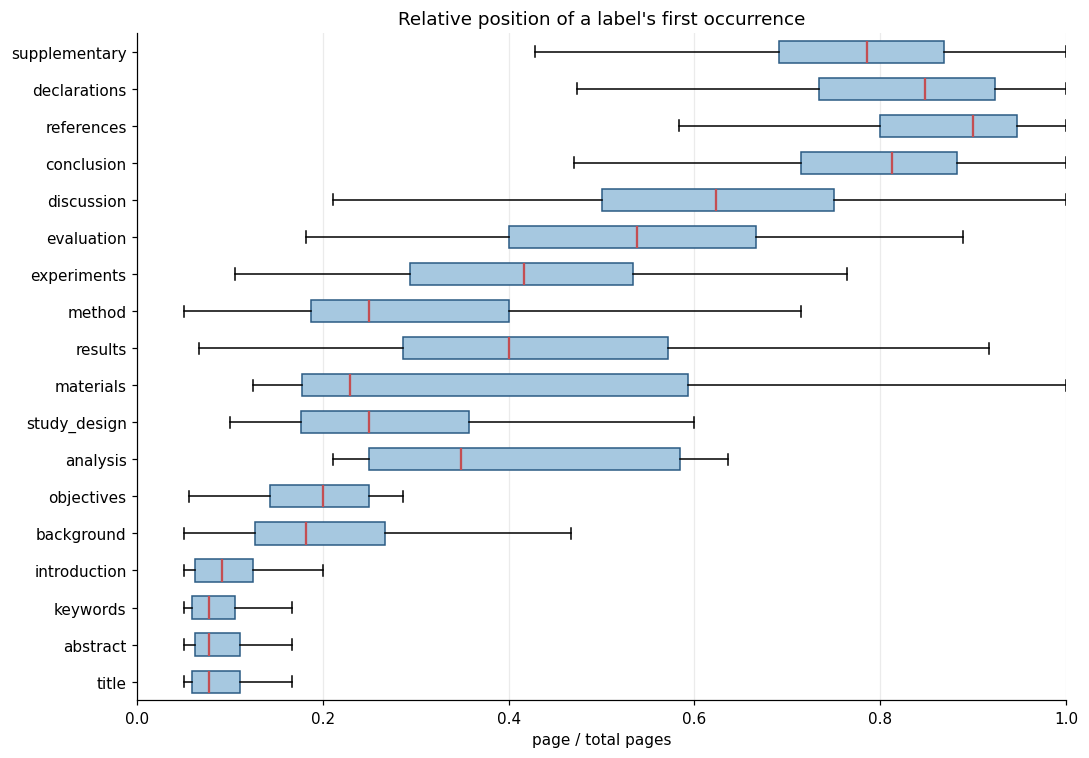

In [7]:
first_pos = defaultdict(list)
for doc_id, rs in by_doc.items():
    seen = set()
    for r in rs:
        for l in r["labels"]:
            if l not in seen:
                seen.add(l)
                first_pos[l].append(r["rel_pos"])

order = [l for l in CANONICAL_LABELS if first_pos[l]]
fig, ax = plt.subplots(figsize=(10, 7))
ax.boxplot([first_pos[l] for l in order], vert=False, labels=order, showfliers=False,
           widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#a6c8e0", edgecolor="#2b5b84"),
           medianprops=dict(color="#c44e52", linewidth=1.5))
ax.set(title="Relative position of a label's first occurrence", xlabel="page / total pages")
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
fig.tight_layout()
savefig("04_first_occurrence")
plt.show()

### Transitions

`P(next | current)` over each article's sequence of first appearances. Read row-wise.
Strong signals: `title -> abstract` (0.98), `abstract -> introduction` (0.81),
`declarations -> references` (0.85).

saved results\figures\05_transitions.png


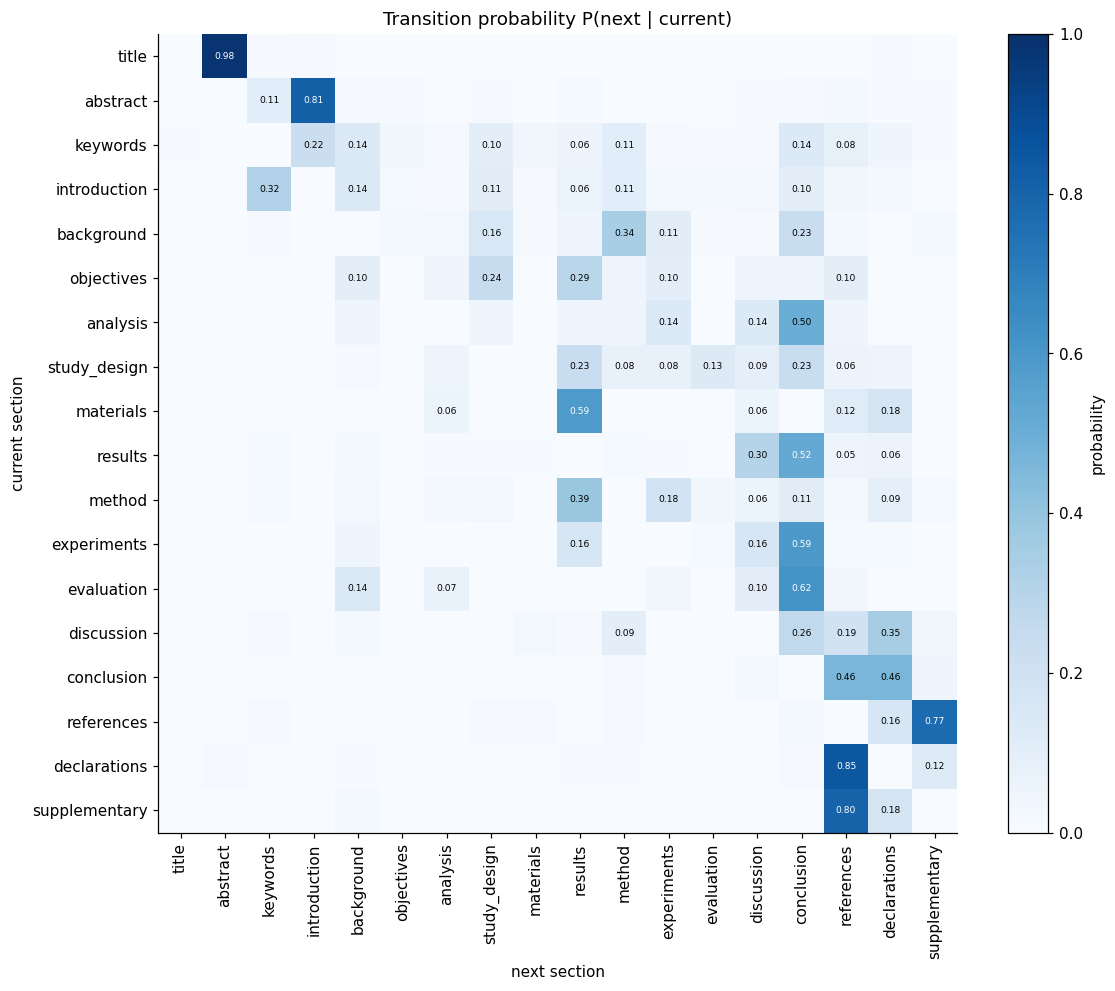

In [8]:
trans = Counter()
for doc_id, rs in by_doc.items():
    seq = []
    for r in rs:
        for l in r["labels"]:
            if l not in seq:
                seq.append(l)
    trans.update(zip(seq, seq[1:]))

M = pd.DataFrame(0, index=list(CANONICAL_LABELS), columns=list(CANONICAL_LABELS))
for (a, b), c in trans.items():
    M.loc[a, b] = c
P = M.div(M.sum(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(P.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CANONICAL_LABELS)))
ax.set_xticklabels(CANONICAL_LABELS, rotation=90)
ax.set_yticks(range(len(CANONICAL_LABELS)))
ax.set_yticklabels(CANONICAL_LABELS)
ax.set(xlabel="next section", ylabel="current section",
       title="Transition probability P(next | current)")
for i in range(len(CANONICAL_LABELS)):
    for j in range(len(CANONICAL_LABELS)):
        v = P.values[i, j]
        if v >= 0.05:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if v > 0.5 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, label="probability")
fig.tight_layout()
savefig("05_transitions")
plt.show()

### Co-occurrence

How often two labels share a page. The diagonal is each label's page count.
Off-diagonal mass is concentrated on `study_design`/`method` and
`declarations`/`references`, which is what makes this a genuine multi-label task.
Color is log-scaled because the values span two orders of magnitude.

saved results\figures\06_cooccurrence.png


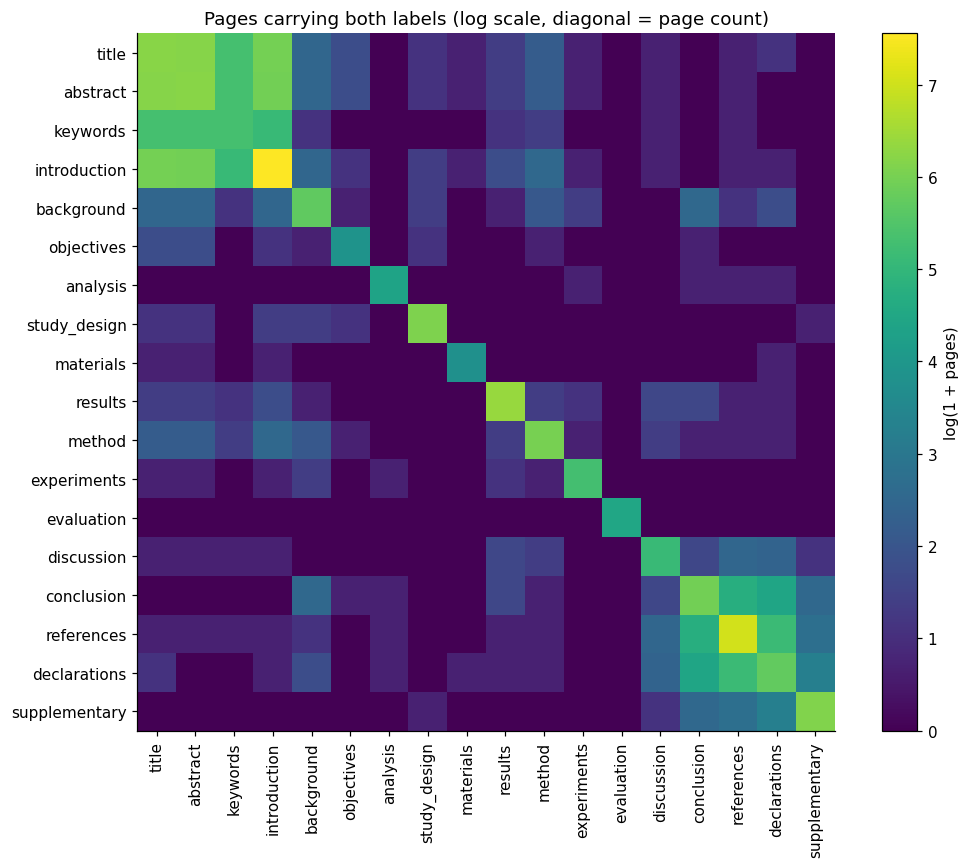

In [9]:
co = pd.DataFrame(0, index=list(CANONICAL_LABELS), columns=list(CANONICAL_LABELS), dtype=int)
for l in CANONICAL_LABELS:
    co.loc[l, l] = cov[l]
for r in rows:
    labels = r["labels_covered"]
    for i, a in enumerate(labels):
        for b in labels[i + 1:]:
            co.loc[a, b] += 1
            co.loc[b, a] += 1

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(np.log1p(co.values), cmap="viridis")
ax.set_xticks(range(len(CANONICAL_LABELS)))
ax.set_xticklabels(CANONICAL_LABELS, rotation=90)
ax.set_yticks(range(len(CANONICAL_LABELS)))
ax.set_yticklabels(CANONICAL_LABELS)
ax.set_title("Pages carrying both labels (log scale, diagonal = page count)")
ax.grid(False)
fig.colorbar(im, ax=ax, label="log(1 + pages)")
fig.tight_layout()
savefig("06_cooccurrence")
plt.show()

## 4. Inheritance

Inherited labels are not guesses: they follow the annotation convention, so the
question is only how long runs get. A long run is normal for `introduction`;
a long run of `results` followed by an unlabelled `discussion` would be an
annotation gap.

saved results\figures\07_inheritance_runs.png


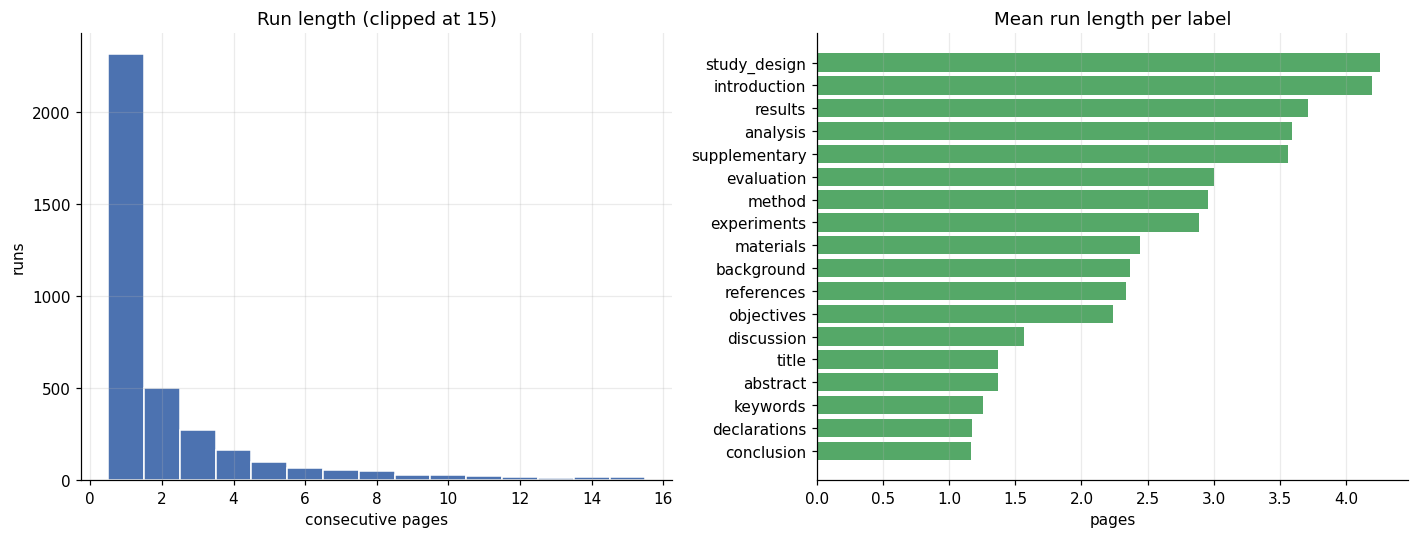

runs 3,661 | mean 2.24 | max 18


,count,mean,max
label,,,
study_design,105,4.26,13
introduction,456,4.20,18
results,159,3.72,16
analysis,22,3.59,8
supplementary,127,3.56,11
evaluation,29,3.00,7
method,138,2.96,14
experiments,70,2.89,14
materials,18,2.44,9


In [10]:
runs = []
for doc_id, rs in by_doc.items():
    active = {}
    last_page = rs[-1]["page"]
    for r in rs:
        present = set(r["labels_covered"])
        for l in list(active):
            if l not in present:
                runs.append((l, r["page"] - active.pop(l)))
        for l in present:
            active.setdefault(l, r["page"])
    for l, start in active.items():
        runs.append((l, last_page - start + 1))

run_df = pd.DataFrame(runs, columns=["label", "length"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(run_df["length"].clip(upper=15), bins=np.arange(0.5, 16.5, 1),
             color="#4c72b0", edgecolor="white")
axes[0].set(title="Run length (clipped at 15)", xlabel="consecutive pages", ylabel="runs")

mean_run = run_df.groupby("label")["length"].mean().sort_values()
axes[1].barh(mean_run.index, mean_run.values, color="#55a868")
axes[1].set(title="Mean run length per label", xlabel="pages")
axes[1].grid(axis="y", visible=False)

fig.tight_layout()
savefig("07_inheritance_runs")
plt.show()

print(f"runs {len(run_df):,} | mean {run_df['length'].mean():.2f} | max {run_df['length'].max()}")
run_df.groupby("label")["length"].agg(["count", "mean", "max"]).round(2).sort_values("mean", ascending=False)

## 5. Splits

Frozen article-level split. Check that the test set is not missing a domain and
that every label has some support -- rare classes will need confidence intervals
rather than a single F1.

saved results\figures\08_splits.png


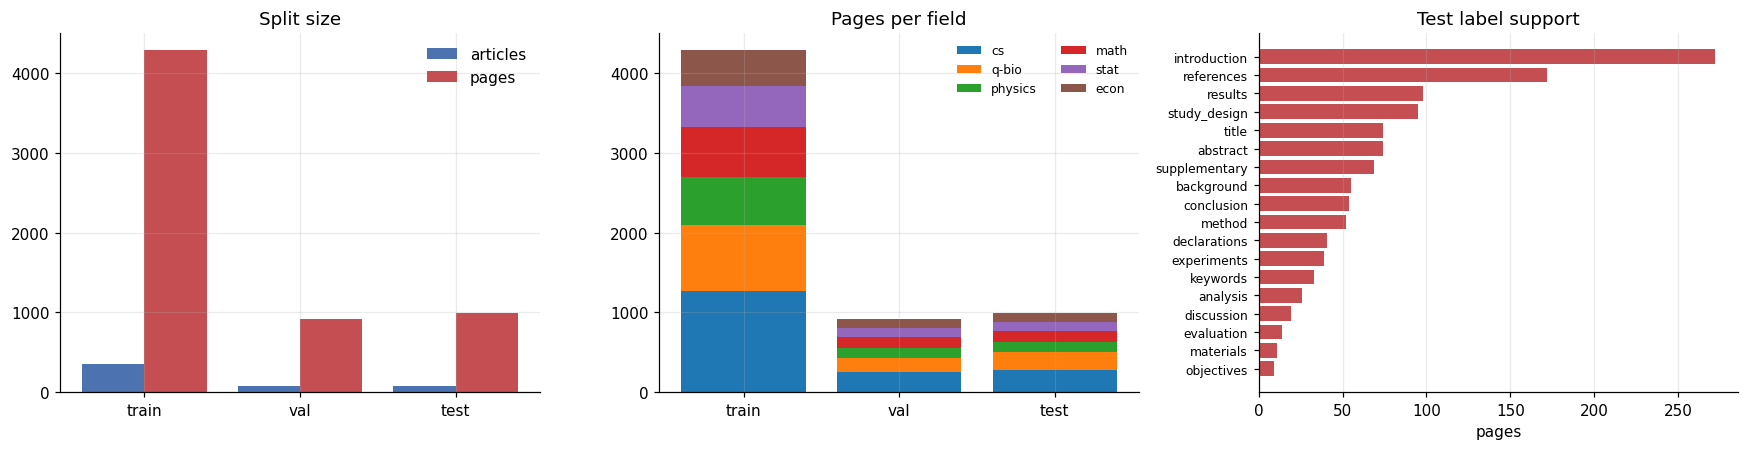

,train,val,test
pages,4289,924,988


In [11]:
split_rows = {}
for name in ("train", "val", "test"):
    split_rows[name] = [json.loads(l) for l in
                        (ROOT / "data/splits" / f"{name}.jsonl").open(encoding="utf-8")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

names = list(split_rows)
n_pages = [len(split_rows[n]) for n in names]
n_articles = [len({r["manuscript_id"] for r in split_rows[n]}) for n in names]
x = np.arange(len(names))
axes[0].bar(x - 0.2, n_articles, 0.4, label="articles", color="#4c72b0")
axes[0].bar(x + 0.2, n_pages, 0.4, label="pages", color="#c44e52")
axes[0].set_xticks(x)
axes[0].set_xticklabels(names)
axes[0].set(title="Split size")
axes[0].legend(frameon=False)

bottom = np.zeros(len(names))
for f in FIELD_ORDER:
    vals = np.array([sum(1 for r in split_rows[n] if r["field"] == f) for n in names])
    axes[1].bar(names, vals, bottom=bottom, label=f)
    bottom += vals
axes[1].set(title="Pages per field")
axes[1].legend(frameon=False, fontsize=8, ncol=2)

test_cov = Counter()
for r in split_rows["test"]:
    test_cov.update(r["labels_covered"])
vals = [test_cov[l] for l in CANONICAL_LABELS]
order_idx = np.argsort(vals)
axes[2].barh(range(len(vals)), [vals[i] for i in order_idx], color="#c44e52")
axes[2].set_yticks(range(len(vals)))
axes[2].set_yticklabels([CANONICAL_LABELS[i] for i in order_idx], fontsize=8)
axes[2].set(title="Test label support", xlabel="pages")
axes[2].grid(axis="y", visible=False)

fig.tight_layout()
savefig("08_splits")
plt.show()

pd.DataFrame({"train": [len(split_rows["train"])], "val": [len(split_rows["val"])],
              "test": [len(split_rows["test"])]}, index=["pages"])

## 6. Text quality

Pages below ~50 characters are extraction failures (a figure caption, a bare page
number). Only two exist; they are listed so they can be excluded or inspected.

saved results\figures\09_text_quality.png


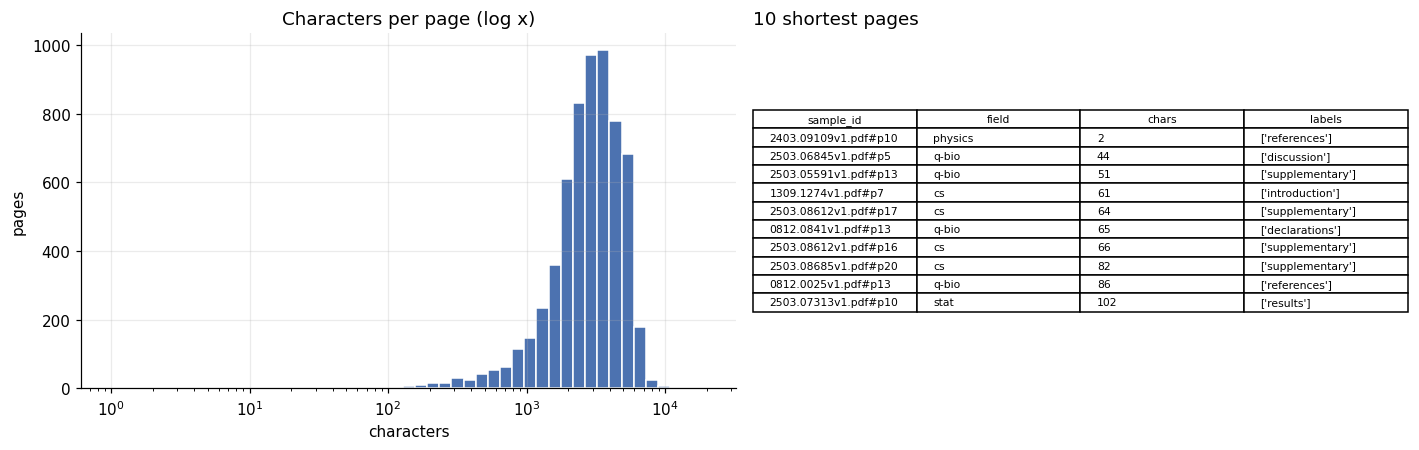

,sample_id,field,n_chars,labels_covered
5106,2403.09109v1.pdf#p10,physics,2,[references]
1092,2503.06845v1.pdf#p5,q-bio,44,[discussion]
1201,2503.05591v1.pdf#p13,q-bio,51,[supplementary]
3448,1309.1274v1.pdf#p7,cs,61,[introduction]
366,2503.08612v1.pdf#p17,cs,64,[supplementary]
4018,0812.0841v1.pdf#p13,q-bio,65,[declarations]
365,2503.08612v1.pdf#p16,cs,66,[supplementary]
45,2503.08685v1.pdf#p20,cs,82,[supplementary]
4004,0812.0025v1.pdf#p13,q-bio,86,[references]
2109,2503.07313v1.pdf#p10,stat,102,[results]


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(df["n_chars"].clip(lower=1), bins=np.logspace(0, 4.3, 50),
             color="#4c72b0", edgecolor="white")
axes[0].set_xscale("log")
axes[0].set(title="Characters per page (log x)", xlabel="characters", ylabel="pages")

short = df.nsmallest(10, "n_chars")[["sample_id", "field", "n_chars", "labels_covered"]]
axes[1].axis("off")
axes[1].set_title("10 shortest pages", loc="left")
axes[1].table(cellText=short.astype(str).values,
              colLabels=["sample_id", "field", "chars", "labels"],
              loc="center", cellLoc="left").auto_set_font_size(False)
axes[1].tables[0].set_fontsize(7)

fig.tight_layout()
savefig("09_text_quality")
plt.show()

short